# Intro

Textual inversion es un método para personalizar modelos text2image como Stable Diffusion. Usando solo unas pocas imágenes puedes enseñar conceptos nuevos y personalizar el modelo con tus propias imágenes. Para todos los detalles de ésta técnica pueden consultar el paper original "[An Image is Worth One Word: Personalizing Text-to-Image Generation using Textual Inversion](https://arxiv.org/abs/2208.01618)" en arxiv.

![Textual Inversion example](https://textual-inversion.github.io/static/images/editing/colorful_teapot.JPG)

Ésta notebook está basada en documentación de Hugging Face disponible en [git](https://github.com/huggingface/diffusers/tree/main/examples/textual_inversion)

# Setup

Previo a comenzar a desarrollar el taller vamos a configurar lo que necesitamos:

* Debemos agregar a nuestro drive en alguna carpeta de su elección las fotos que vamos a utilizar para que la AI nos conozca. Lo genial de todo este proceso es que no necesitamos demasiadas, entre 3 y 5 es suficiente. Si lo deseamos podemos agregar algunas más, para mi ejemplo utilizo 7 pero diría que no necesitan más de 12. Busquen en particular que la mayoría sea con sus caras bien visibles y otras que sean de cuerpo entero para que también el modelo vea ejemplos de sus posturas.
* En el mismo directorio donde se encuentre la carpeta con nuestras fotos vamos a descargar ésta notebook y abrirla desde ahí.

Por ejemplo:

```
root
├── sample_fotos
│   ├── foto1.jpg
│   ├── foto2.jpg
│   └── ...
└── colab_notebook.ipynb
```

Una vez hecho lo anterior podemos correr las siguiente celda para montar nuestro Google Drive.

In [ ]:
# Vamos a importar dentro de Colab nuestro google drive.
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


**Nota**: Chequear el uso de GPU en settings de la notebook: `Runtime --> Change runtime type` y seleccionar otra cosa que no sea CPU (dependiendo de la suscripción a google colab tendran diferentes opciones).

Ahora simplemente vamos a definir una variable con la ruta a la carpeta elegida en Google Drive, para hacerlo más simple podemos hacer click secundario en nuestra carpeta (en la jerarquía) y elegir la opción "Copy path"

In [ ]:
#@markdown `IMAGES_PATH` es la ruta donde se encuentra nuestras
IMAGES_PATH = "/content/drive/MyDrive/GDG_Medellín/sample_fotos" #@param {type:"string"}

Vamos a chequear si estamos corriendo en GPU y bajo qué características.

In [ ]:
# Check type of GPU and VRAM available.
!nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv,noheader

NVIDIA L4, 23034 MiB, 22698 MiB


Luego pasaremos a instalar los requerimientos y librerías necesarias para correr nuestra pequeña demo.

Empezamos por la librería [diffusers](https://huggingface.co/docs/diffusers/en/index), principal librería para el uso de modelos de difusión.

In [ ]:
!pip install -U -qq git+https://github.com/huggingface/diffusers.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Ahora instalamos un par de librerías auxiliares que nos pueden permitir a hacer más eficiente nuestro entrenamiento e inferencia, como el uso de [xformers](https://huggingface.co/docs/diffusers/en/optimization/xformers) and [bitsandbytes](https://huggingface.co/docs/bitsandbytes/main/en/index).

In [ ]:
!pip install -qq "accelerate>=0.16.0" torchvision "transformers>=4.25.1" ftfy tensorboard gradio xformers Jinja2
!pip install -qq "ipywidgets>=7,<8"
!pip install -qq bitsandbytes
!pip install -U --pre triton

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.6/50.6 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.7/56.7 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.8/319.8 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.6/94.6 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.4/76.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.0/78.0 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.4/447.4 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 109.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.2/73.2 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7

Necesitamos descargar ahora el script que nos va a permitir realizar nuestro finetuning

In [ ]:
!wget -q https://raw.githubusercontent.com/huggingface/diffusers/main/examples/textual_inversion/textual_inversion.py

## Imports

In [ ]:
import PIL
from PIL import Image

from os.path import exists, join, isfile, realpath, isdir, basename, dirname
from os import listdir, makedirs

from diffusers import StableDiffusionPipeline
import torch

from accelerate.utils import write_basic_config

from tqdm.auto import tqdm

from IPython.display import clear_output
from IPython.display import Image as ipImage
from IPython.display import HTML
from IPython import display as ipythondisplay

import base64
import io

from datetime import datetime, timedelta

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [ ]:
write_basic_config()

PosixPath('/root/.cache/huggingface/accelerate/default_config.yaml')

## Utilidades

Algunas funciones para el manejo de archivos

In [ ]:
# Para listar directorios de una ruta
def get_dirs(dir_path: str, include_hidden_files: bool=False):
    dirs = [d for d in listdir(dir_path) if isdir(join(dir_path, d)) and (not d.startswith(".") or (d.startswith(".") and include_hidden_files))]
    return dirs

In [ ]:
# Para listar archivos de una ruta
def get_dir_files(dir_path: str):
    return [f for f in listdir(dir_path) if isfile(join(dir_path, f))]

In [ ]:
# Para mostrar imágenes en grilla de html.
def image_to_byte_array(image: Image, format="jpeg") -> bytes:
  bytes_array = io.BytesIO()
  image.save(bytes_array, format=format)
  bytes_array = bytes_array.getvalue()

  return bytes_array

Para crear una tabla HTML y mostrar las imágenes.

In [ ]:
# para mostrar imágenes
def show_img_comparison(images, resolution: int=512):
    begin_table =f"""
            <table>
                <thead> {[f"<th>{i}</th>" for i in range(len(images))]}
                <thead>
                <tbody>
                <tr>"""
    end_table = """
                    </tr>
                <tbody>
            </table>
        """

    mid_table = ""
    for img in images:
        encoded = base64.b64encode(image_to_byte_array(img))
        mid_table += f"""<td>
                        <img <source src="data:image/jpeg;base64,{encoded.decode('ascii')}" type="image/jpeg" height="{resolution}"/>
                        </img>
                        </td>
            """

    table = begin_table + mid_table + end_table
    ipythondisplay.display(HTML(data=table))

Antes de continuar veamos algo lo que hemos seleccionado entonces para el finetuning de nuestro modelo.

images


,,,

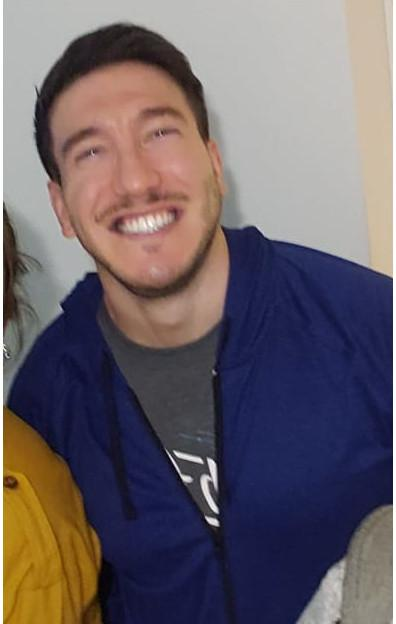
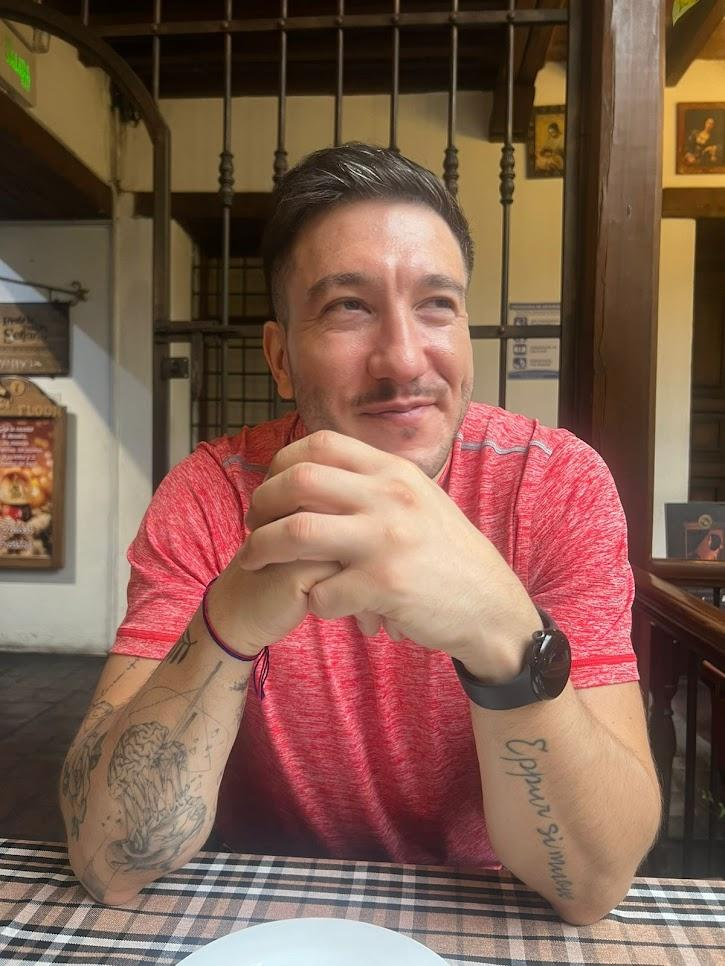
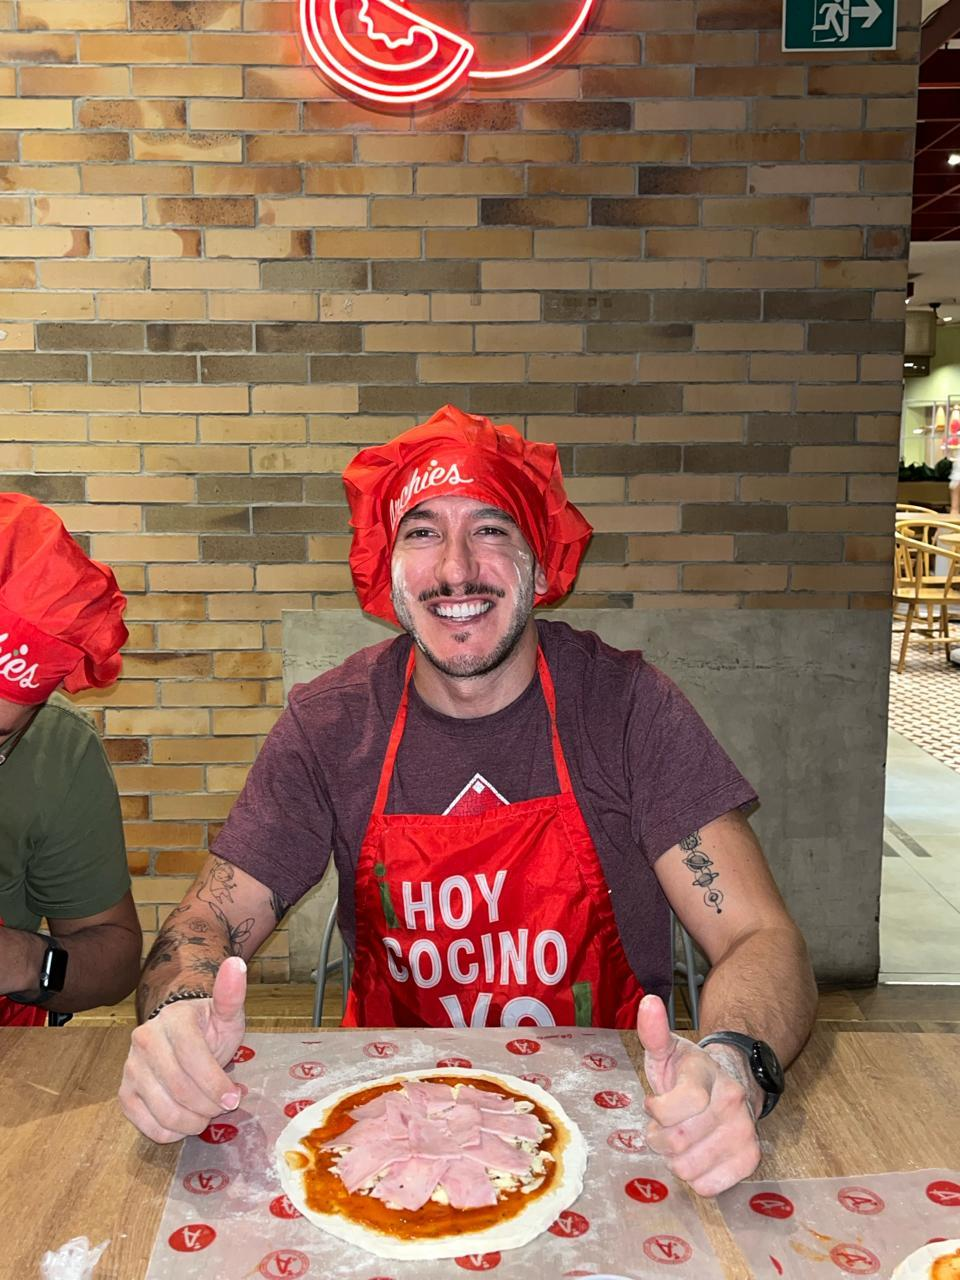
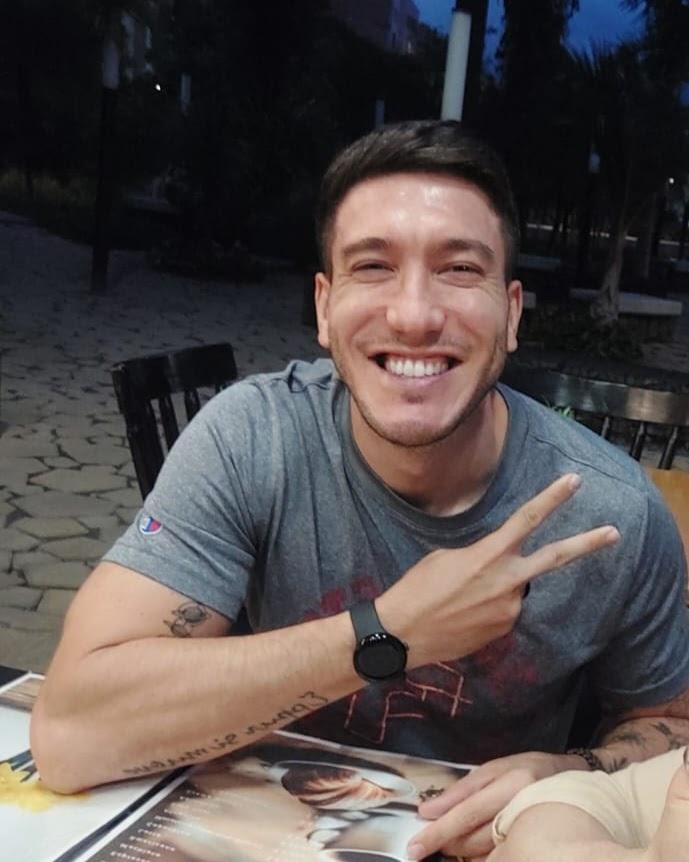

In [ ]:
images = get_dir_files(IMAGES_PATH)
images2show = []
for img in images[0:4]:
    image = Image.open(join(IMAGES_PATH, img))
    images2show.append(image)

print("images")
show_img_comparison(images2show, resolution=256)

# Dándonos a conocer

Con tan sólo unas pocas imágenes somos capaces de enseñarle un nuevo concepto al modelo mediante el uso de textual inversion. Generalmente ésto funciona mejor para transferir estilos pero sólo para probar veremos qué resulta de darnos a conocer.

Vamos ahora a crear nuestra carpeta para almacenar nuestro modelo.

Por defecto está para que se guarde en la VM que nos presta google, pero tener presente que ni bien termine el modelo debemos descargarla a nuestro disco para no perder el contenido, ya que luego de un tiempo la máquina se da de baja y se elimina todo su contenido. O la otra opción es guardarla directamente dentro de nuestro google drive en cualquier carpeta dentro de `/content/drive/MyDrive`.

In [ ]:
# @title Elegir dónde vamos a guardar nuestro modelo
# @markdown `OUTPUT_DIR` es la ruta donde guardaremos nuestro modelo
OUTPUT_DIR = "/content/drive/MyDrive/GDG_Medellín/finetuned_models/my_model_ti" # @param {type:"string"}

if not exists(OUTPUT_DIR):
    !mkdir -p "$OUTPUT_DIR"

In [ ]:
# @title Instrucciones para enseñarle un nuevo concepto
# @markdown `WHAT_TO_TEACH`: ¿Qué es lo que le estamos enseñando? por ejemplo `object` te habilita a enseñarle un nuevo objeto a ser usado, `style` te permite enseñarle un nuevo estilo a utilizar. Dejaremos por defect `object`.
WHAT_TO_TEACH = "object" # @param ["object", "style"]
# @markdown `PLACEHOLDER_TOKEN` es el token que vamos a utilizar para representar el nuevo concepto, de manera de utilizar luego un prompt al modelo del estilo "A `<my-placeholder-token>` in an amusement park". Usamos las llaves para diferenciar el token de otras palabras/tokens que puedan causar alguna colisión de conceptos.
PLACEHOLDER_TOKEN = "<mauri>" # @param {type:"string"}
# @markdown `INITIALIZER_TOKEN` es una palabra que resume lo que es el nuevo concepto para usarlo como punto de partida.
INITIALIZER_TOKEN = "man" # @param {type:"string"}
# @markdown `MAX_TRAINING_STEPS` es la cantidad máxima de pasos que vamos a utilizar para finetunear nuestra red. No hay nada empírico así que simplemente vamos a hacer un pequeño número de pasos para tener una noción de cómo funciona nuestro modelo.
MAX_TRAINING_STEPS = 2100 # @param {type:"integer"}

In [ ]:
# @title Selección de nuestro modelo de difusión.
# @markdown `MODEL`: Establecemos nuestro modelo de preferencia, que en este caso será la versión 2.1, si quisieramos usar otras versiones hay que tener presente que la resolución podría necesitar ajustes.
MODEL = "stabilityai/stable-diffusion-2-1" # @param ["Jiali/stable-diffusion-1.5", "runwayml/stable-diffusion-v1-5", "stabilityai/stable-diffusion-2-1"]

Nota: StabilityAI solicitó la baja de runwayml/stable-diffusion-v1-5.

## Training

Ya tenemos todo listo, ahora corramos nuestro script.

Bajo esta configuración de parámetros y con una GPU T4 nuestro script de finetuning debería demorar 1 hora aproximadamente en terminar.

**Nota**: Si tuvieramos más de una GPU (lucky you!) podríamos utilizar la librería [`accelerate`](https://github.com/huggingface/accelerate) para correr nuestro script.

In [ ]:
start_time = datetime.now()
print(f"Starting training at {str(start_time)}")

Starting training at 2024-10-23 22:14:26.030152


In [ ]:
!python3 textual_inversion.py \
  --pretrained_model_name_or_path="$MODEL" \
  --train_data_dir="$IMAGES_PATH" \
  --learnable_property="$WHAT_TO_TEACH" \
  --placeholder_token="$PLACEHOLDER_TOKEN" \
  --initializer_token="$INITIALIZER_TOKEN" \
  --resolution=768 \
  --train_batch_size=1 \
  --gradient_accumulation_steps=4 \
  --max_train_steps=$MAX_TRAINING_STEPS \
  --learning_rate=5.0e-04 \
  --scale_lr \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --output_dir="$OUTPUT_DIR" \
  --seed=1337

2024-10-23 22:14:30.816658: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-23 22:14:30.837608: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-23 22:14:30.843934: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-23 22:14:32.105174: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
10/23/2024 22:14:34 - INFO - __main__ - Distributed environment: NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: no

tokenizer/tokenizer_config.json: 100% 824/824 [00:00<00:00, 5.57MB/s]
tokeni

In [ ]:
end_time = datetime.now();
print(f"Ending training at {str(end_time)}")

elapsed_time = end_time - start_time

sec = elapsed_time.total_seconds() % (24 * 3600)
hour = sec // 3600
sec %= 3600
min = sec // 60
sec %= 60
print(f">>>>> Total elapsed time: {round(hour)}:{round(min)}:{sec}. <<<<<")

Ending training at 2024-10-24 00:30:14.379498
>>>>> Total elapsed time: 2:15:48.34934599999997. <<<<<


# Inference

Ahora vamos a ver qué tan bien nos conoció la AI. Primero pasaremos a cargar el modelo base que usamos durante el finetuning utilizando una [pipeline](https://huggingface.co/docs/diffusers/en/api/pipelines/overview).

Las pipelines proporcionan una manera sencilla de ejecutar DMs, agrupando los componentes necesarios (modelos entrenados de forma independiente, schedulers y procesadores) en una única clase end-to-end. Las pipelines son flexibles y se pueden adaptar para utilizar diferentes schedulers o incluso otros componentes del modelo.

Por último cargaremos los resultados del finetuning por textual inversion.

**Obs**: Al crear la pipeline vamos a estar utilizando el parámetro `safety_checker` en `None`, el mismo se utiliza para evitar generar contenido NSFW (contenido sexual, violento, etc) por parte del modelo, muchas veces no funciona bien ya que aún no siendo imágenes del estilo puede llegar a prohibir el contenido (devolviendo una imagen en negro). Por esa razón en nuestro caso dejaremos deshabilitado dicho filtro.

In [ ]:
pipe = StableDiffusionPipeline.from_pretrained(MODEL, safety_checker=None, torch_dtype=torch.float16).to("cuda")
pipe.load_textual_inversion(OUTPUT_DIR)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


model_index.json:   0%|          | 0.00/537 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

(…)ature_extractor/preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


**Nota**: durante la creación del pipeline también es posible cambiar el [scheduler](https://huggingface.co/docs/diffusers/en/using-diffusers/schedulers) que se utiliza, teniendo ésto un impacto importante en el resultado final que se obtiene.


El scheduler encapsula todo el proceso de eliminación de ruido (denoising process), como el número de pasos y el algoritmo para encontrar la muestra sin ruido. Un scheduler no está parametrizado ni entrenado, por lo que no requiere mucha memoria. Por lo general, el modelo solo se ocupa del forward pass, es decir de pasar de una entrada ruidosa a una menos ruidosa.


Podemos chequear cuál es el scheduler que tenemos de la siguiente manera:

In [ ]:
pipe.scheduler

DDIMScheduler {
  "_class_name": "DDIMScheduler",
  "_diffusers_version": "0.32.0.dev0",
  "beta_end": 0.012,
  "beta_schedule": "scaled_linear",
  "beta_start": 0.00085,
  "clip_sample": false,
  "clip_sample_range": 1.0,
  "dynamic_thresholding_ratio": 0.995,
  "num_train_timesteps": 1000,
  "prediction_type": "v_prediction",
  "rescale_betas_zero_snr": false,
  "sample_max_value": 1.0,
  "set_alpha_to_one": false,
  "skip_prk_steps": true,
  "steps_offset": 1,
  "thresholding": false,
  "timestep_spacing": "leading",
  "trained_betas": null
}

Los schedulers tienen sus pros y cons, lo que dificulta comparar cuantitativamente cuál funciona mejor para una pipeline determinada. Por lo general, es necesario tener un balance entre la velocidad y la calidad de eliminación de ruido. La recomendación es siempre probar diferentes schedulers para encontrar el que mejor se adapte al caso de uso.

Para probar con un scheduler distinto podríamos hacer lo siguiente:
```
import torch
from diffusers import DDIMScheduler, DiffusionPipeline

ddim = DDIMScheduler.from_pretrained(MODELO, subfolder="scheduler")

pipeline = DiffusionPipeline.from_pretrained(
    MODELO, scheduler=ddim, torch_dtype=torch.float16, use_safetensors=True
).to("cuda")
```

In [ ]:
# @title Instrucciones para generar imágenes (I)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A photo of a <mauri> man posing with the Everest mountain in the background" # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 5 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

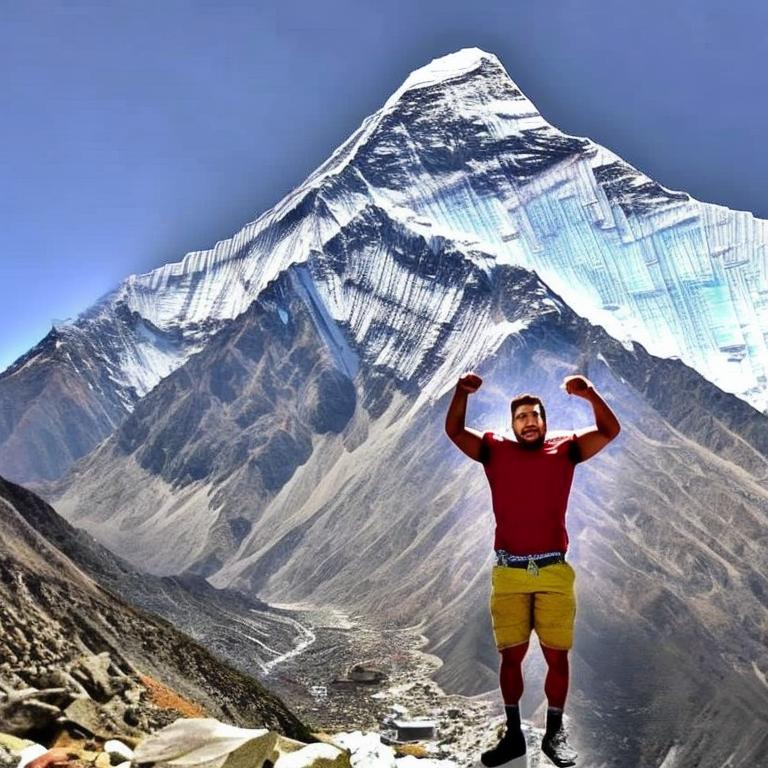
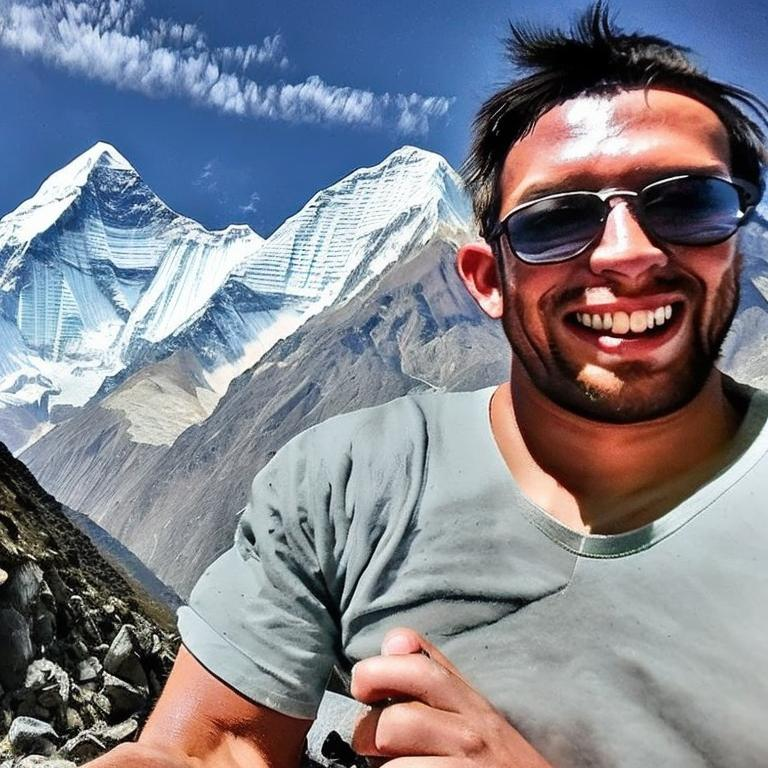
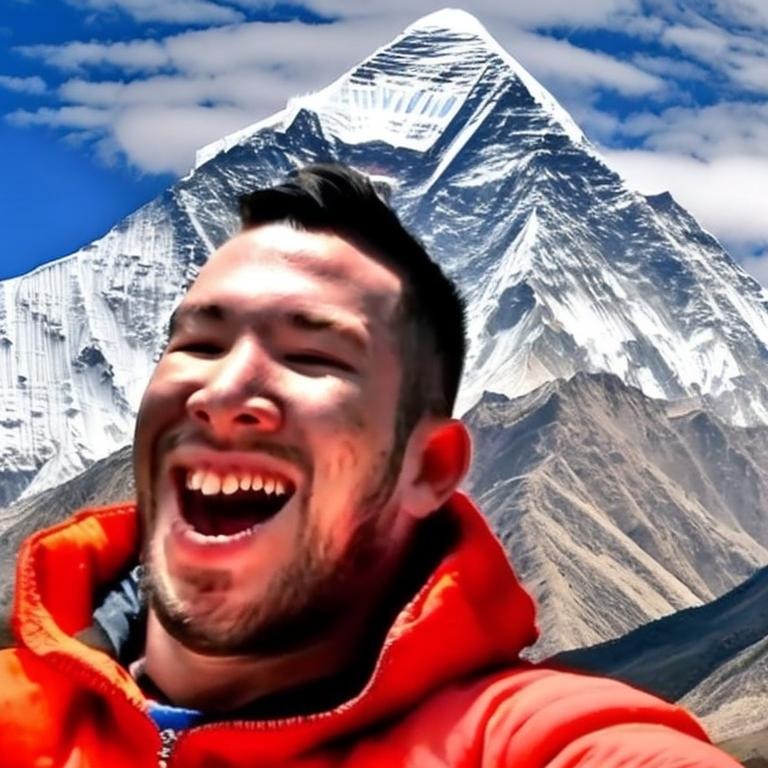
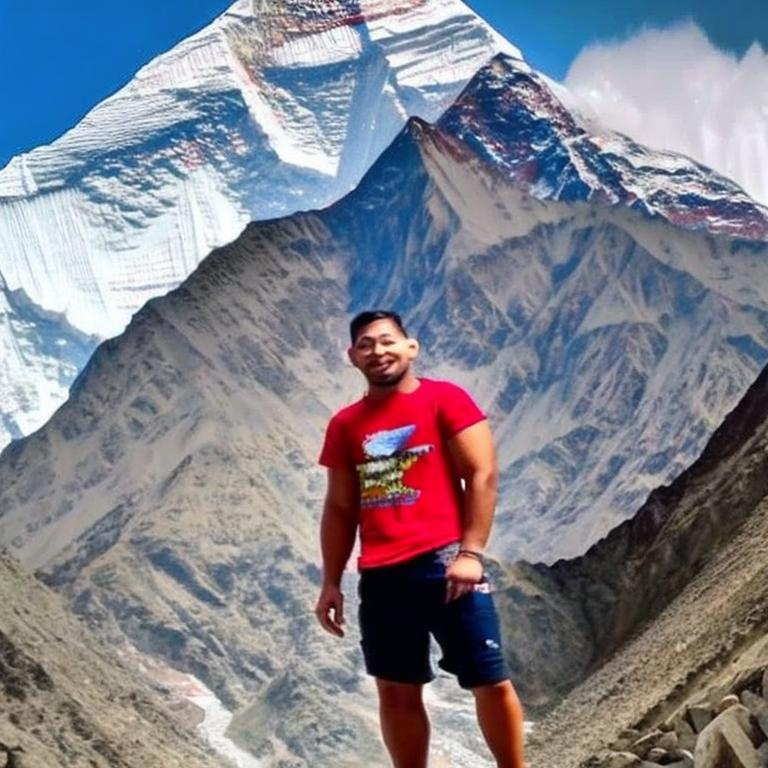
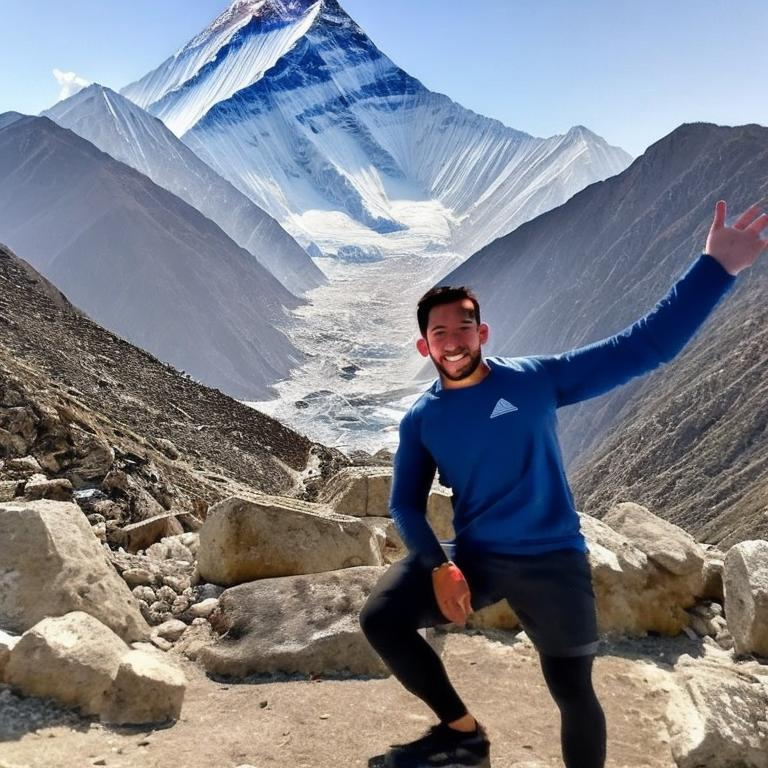

In [ ]:
imgs2test = []
for img in range(0, 5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

In [ ]:
# @title Instrucciones para generar imágenes (II)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A beatiful medieval painting of <mauri> man in a castle with a dragon spitting fire in the background, all inspired in game of thrones." # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 5 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

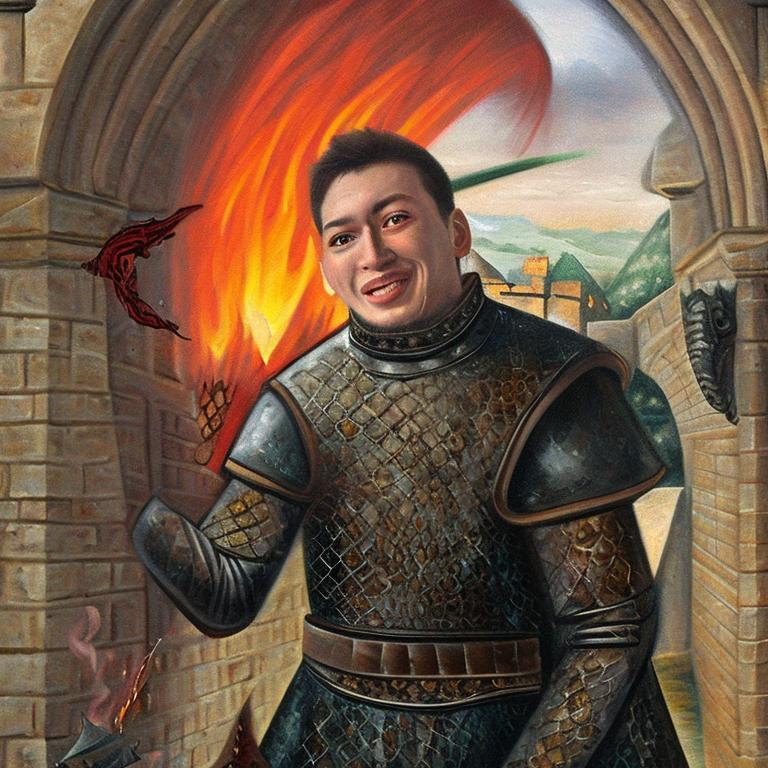
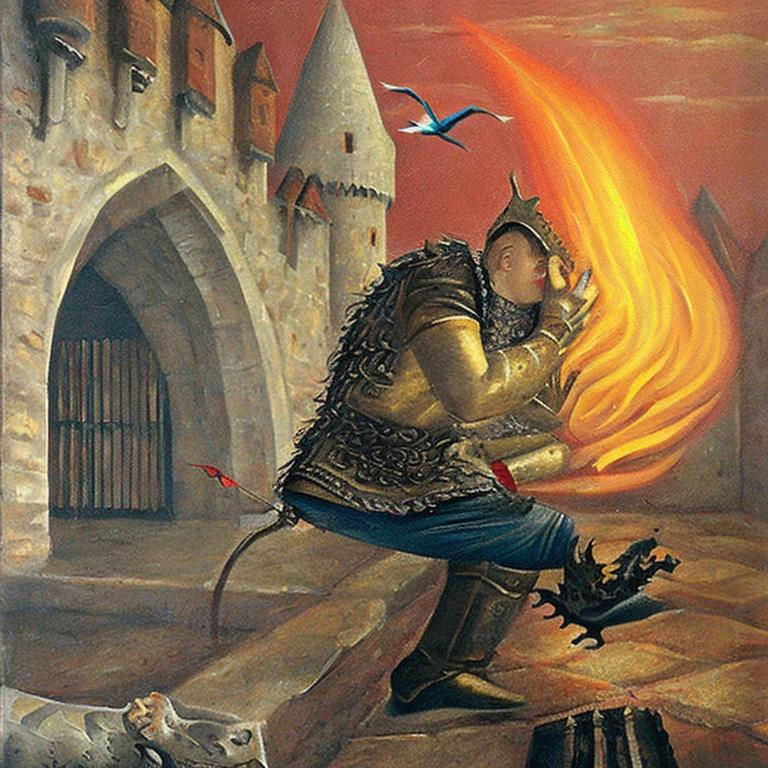
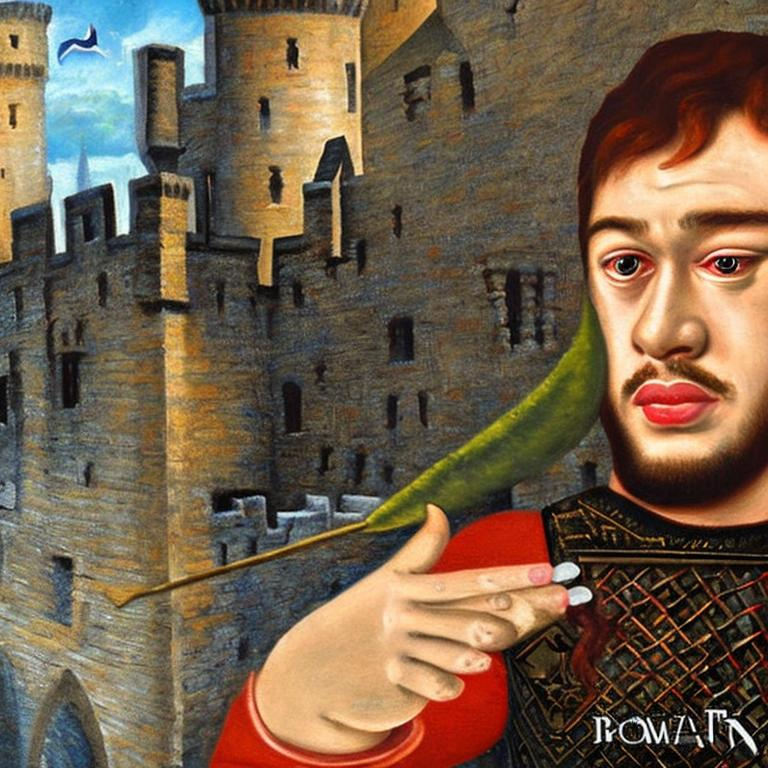
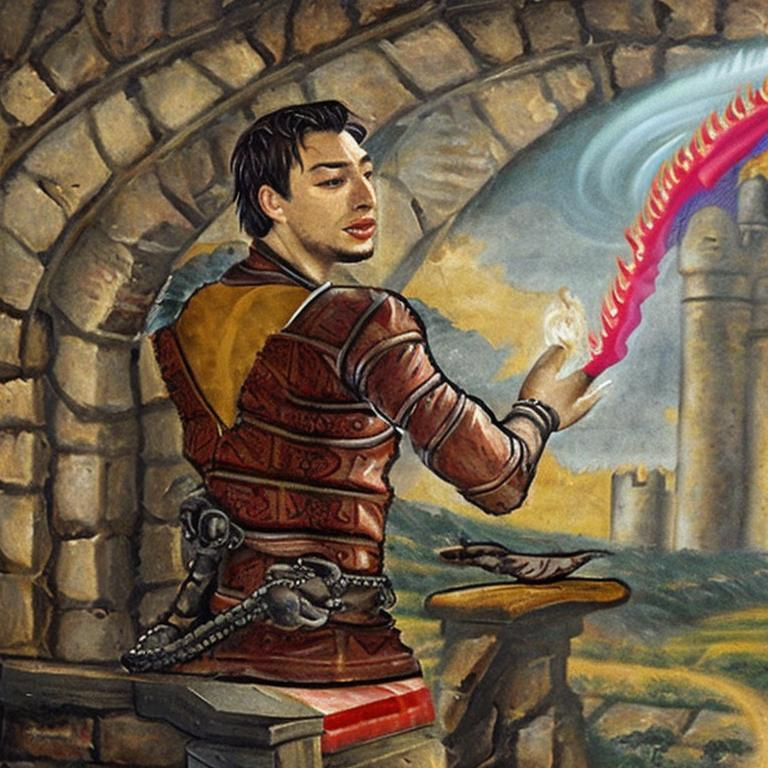
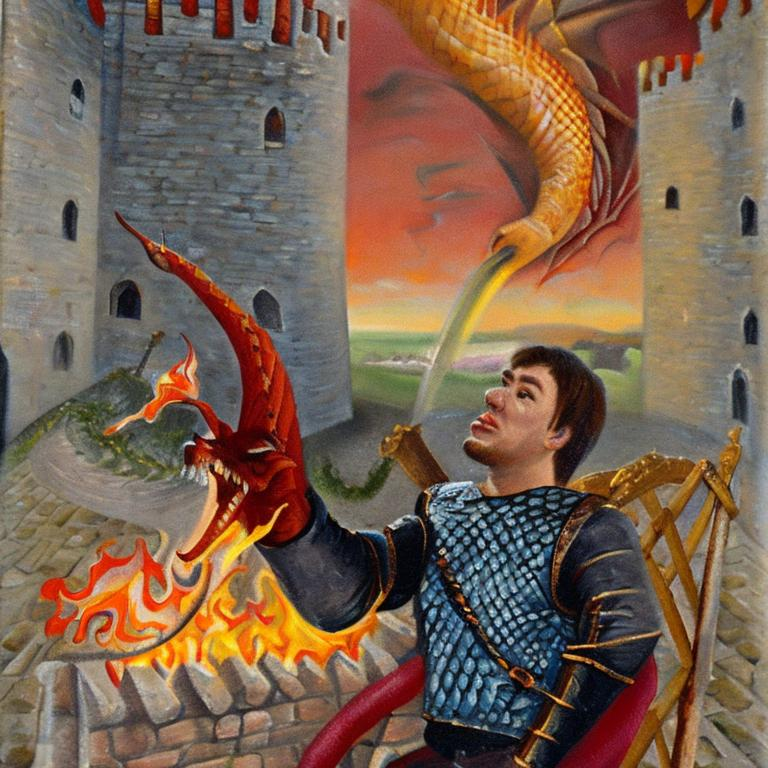

In [ ]:
imgs2test = []
for img in range(0, 5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

In [ ]:
# @title Instrucciones para generar imágenes (III)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A <mauri> man portrait as a rock star with kiss make-up." # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 5 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

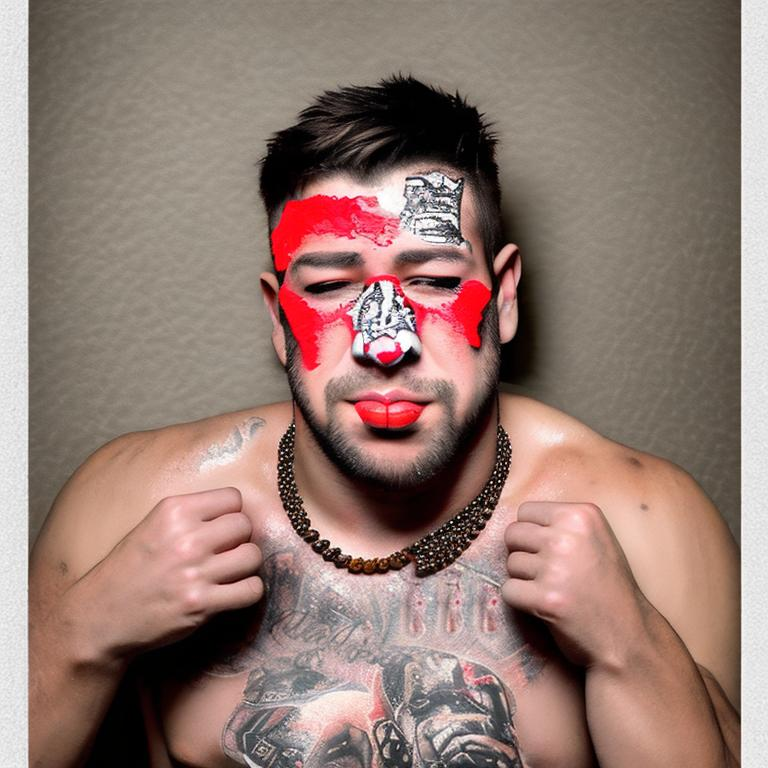
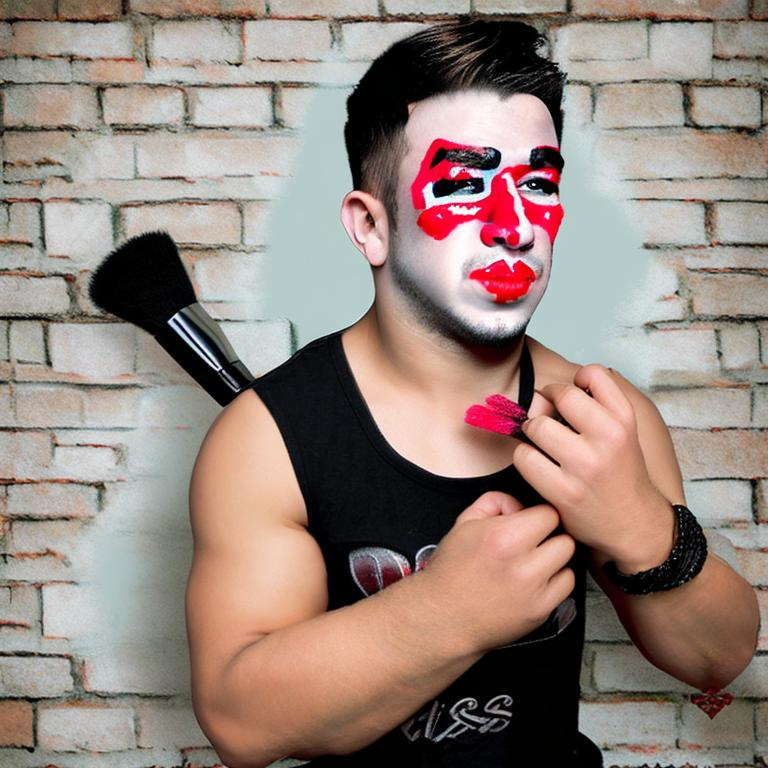
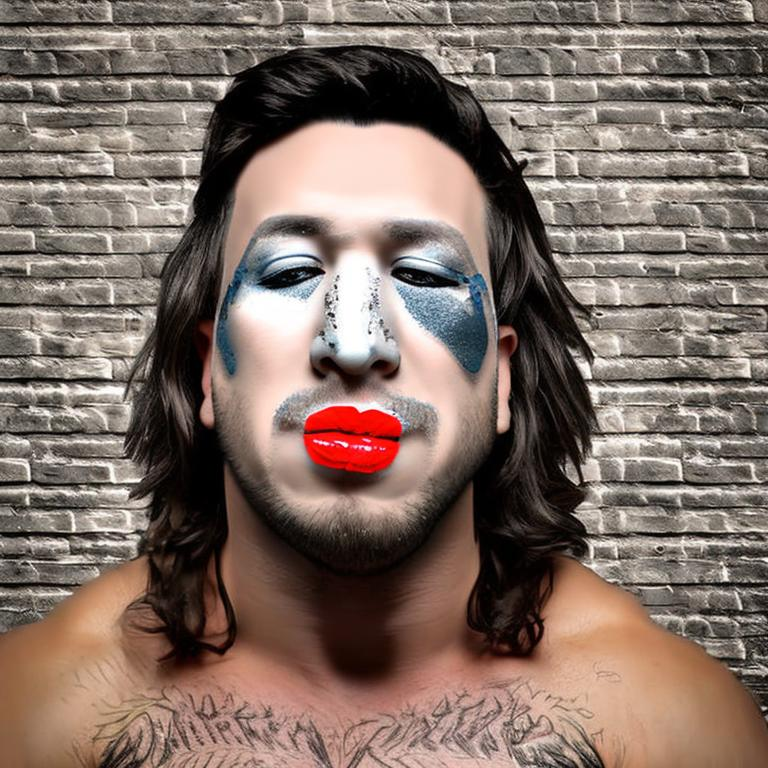
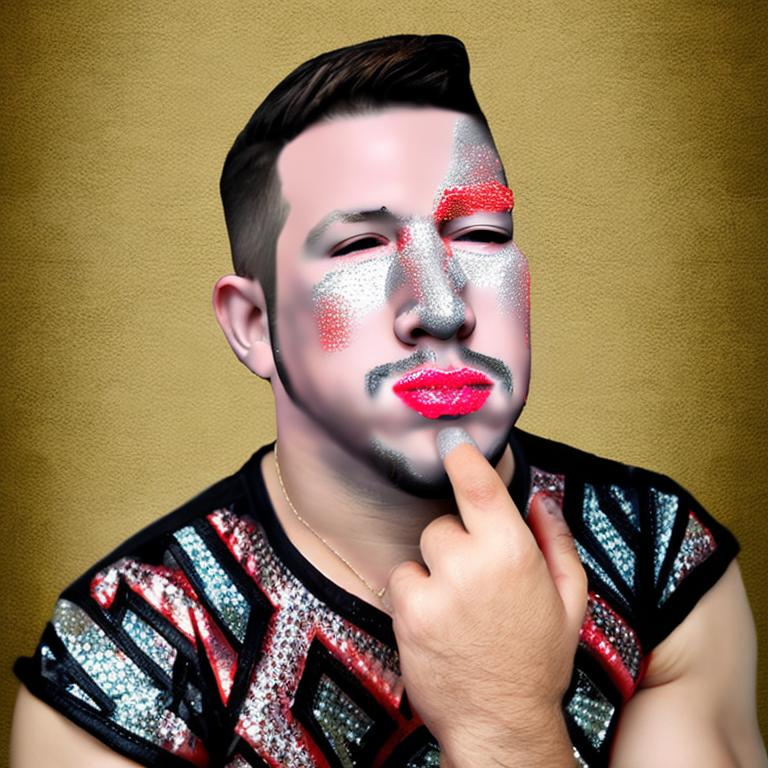
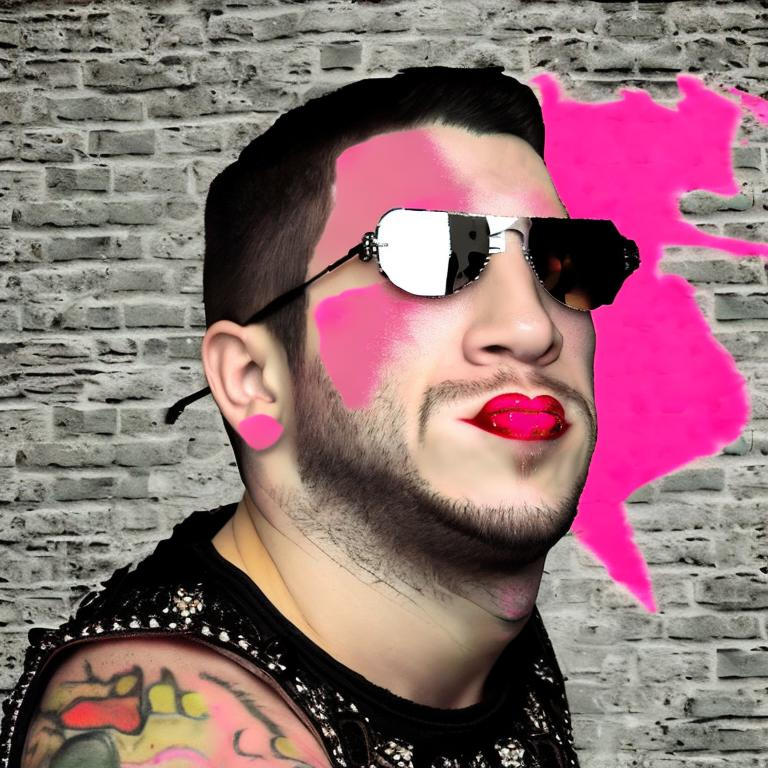

In [ ]:
imgs2test = []
for img in range(0, 5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

#### Comparación con SD1.5

"A photo of a smiling \<mauri\> man posing with the Everest mountain in the background"
<table>
<tr>
<td><img src="https://i.imgur.com/idr1SzG.png" width="250"></td>
<td><img src="https://i.imgur.com/mNuQyyd.png" width="250"></td>
</tr>
</table>

"A beatiful medieval painting of \<mauri\> man in a castle with a dragon spitting fire in the background, all inspired in game of thrones."
<table>
<tr>
<td><img src="https://i.imgur.com/weaCzAL.png" width="250"></td>
<td><img src="https://i.imgur.com/RaesPDA.png" width="250"></td>
</tr>
</table>

"A \<mauri\> man portrait as a rock star with kiss make-up."
<table>
<tr>
<td><img src="https://i.imgur.com/HGUvs0h.png" width="250"></td>
<td><img src="https://i.imgur.com/1VmuR6Z.png" width="250"></td>
</tr>
</table>

Eventualmente si desean usar éstos modelos de forma más interactiva podrían probar con una [WebUI](https://github.com/AUTOMATIC1111/stable-diffusion-webui) de Automatic1111 que resulta fácil y divertido de utilizar. Hay también notebooks disponibles para levantar dicha interfaz desde el navegador [aquí](https://github.com/AUTOMATIC1111/stable-diffusion-webui/wiki/Online-Services).